# Class imbalance, decision thresholds and learning curves

**Module 03.2 · my implementation**, Seid Adem

This continues [notebook 01](01_mr_audit_leakage_nested_cv.ipynb) on the molecular-replacement (MR) dataset, with
the same cleaned data, the course's 27 pre-MR features, and **splits by crystal**. It answers three practical
questions:

1. **When one outcome is rare, what do class weights, oversampling, SMOTE and undersampling actually change?**
2. **Is the decision threshold the real lever?**
3. **Would more data, or a more complex model, help?** (learning and validation curves)

> **New to these ideas?** See [imbalanced classes](../LESSONS.md#lesson-4--imbalanced-classes-resampling-and-class-weights) and
> [reading performance metrics](../LESSONS.md#lesson-6--reading-performance-metrics). Key terms used below:
> * **Recall:** of the real successes, what fraction did the model find?
> * **Precision:** of the attempts the model *predicted* to succeed, what fraction really did?
> * **PR-AUC (average precision):** precision and recall summarised over all thresholds. A random model scores the
>   success rate itself (0.44 here, 0.10 in the rare scenario), not 0.5.
> * **Threshold:** a model outputs a score between 0 and 1; "predict success if score ≥ 0.5" is just a default.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import (
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    learning_curve,
    validation_curve,
)
from sklearn.preprocessing import StandardScaler

from dsls.mr import COURSE_FEATURES, GROUP, LABEL, load_mr_data, subsample_prevalence

DATA = Path("../course_materials/DataScience_EBI/tutorials/data.csv")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", category=UserWarning)
SEED = 0

df = load_mr_data(DATA)
print(f"{len(df)} rows, {df[GROUP].nunique()} crystals, success rate {df[LABEL].mean():.0%}")

663 rows, 359 crystals, success rate 44%


## 1 · Five ways to handle imbalance, in leakage-safe pipelines

> **In plain language.** If successes are rare, a model can score well by mostly predicting "failure". Four common
> remedies:
>
> | Strategy | What it does |
> |----------|-------------|
> | **Class weights** | mistakes on the rare class count more during training; no data is changed |
> | **Random oversampling** | duplicates rare-class rows in the training data |
> | **SMOTE** | creates *synthetic* rare-class rows by interpolating between real neighbours |
> | **Random undersampling** | throws away common-class rows until the classes are balanced |
>
> **Resampling must only touch the training part of each split.** The test part must keep the real-world class
> balance. `imblearn`'s `Pipeline` guarantees this: resampling steps run during `fit` only, never during prediction.

In [2]:
STRATEGIES = ["none", "class weights", "random oversampling", "SMOTE", "random undersampling"]
RESAMPLERS = {
    "random oversampling": RandomOverSampler,
    "SMOTE": SMOTE,
    "random undersampling": RandomUnderSampler,
}
METRICS = {
    "roc_auc": "ROC-AUC",
    "average_precision": "PR-AUC",
    "balanced_accuracy": "balanced accuracy",
    "recall": "recall",
    "precision": "precision",
}


def make_pipeline(model_name, strategy):
    steps = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    if strategy in RESAMPLERS:
        steps.append(("resample", RESAMPLERS[strategy](random_state=SEED)))
    weights = "balanced" if strategy == "class weights" else None
    if model_name == "logistic regression":
        model = LogisticRegression(max_iter=5000, class_weight=weights)
    else:  # shallow forest, in line with the settings nested CV preferred in notebook 01
        model = RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=10,
            random_state=SEED,
            n_jobs=4,
            class_weight=weights,
        )
    return Pipeline([*steps, ("model", model)])


def evaluate(data, seeds):
    rows = []
    for model_name in ["logistic regression", "random forest"]:
        for strategy in STRATEGIES:
            for seed in seeds:
                cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
                res = cross_validate(
                    make_pipeline(model_name, strategy),
                    data[COURSE_FEATURES],
                    data[LABEL],
                    groups=data[GROUP],
                    cv=cv,
                    scoring=list(METRICS),
                )
                rows.append(
                    {
                        "model": model_name,
                        "strategy": strategy,
                        "seed": seed,
                        **{label: res[f"test_{key}"].mean() for key, label in METRICS.items()},
                    }
                )
    return pd.DataFrame(rows).groupby(["model", "strategy"], sort=False).mean().drop(columns="seed")


natural = evaluate(df, seeds=range(3))
natural.round(3)

ROC-AUC  PR-AUC  balanced accuracy  \
model               strategy                                                   
logistic regression none                    0.737   0.729              0.688   
                    class weights           0.736   0.729              0.687   
                    random oversampling     0.730   0.726              0.684   
                    SMOTE                   0.734   0.729              0.686   
                    random undersampling    0.728   0.723              0.685   
random forest       none                    0.751   0.747              0.722   
                    class weights           0.749   0.745              0.711   
                    random oversampling     0.746   0.746              0.715   
                    SMOTE                   0.748   0.747              0.720   
                    random undersampling    0.745   0.739              0.705   

                                          recall  precision  
model               strategy                                 
logistic regression none                   0.566      0.711  
                    class weights          0.617      0.673  
                    random oversampling    0.615      0.670  
                    SMOTE                  0.620      0.671  
                    random undersampling   0.615      0.670  
random forest       none                   0.609      0.748  
                    class weights          0.636      0.707  
                    random oversampling    0.636      0.715  
                    SMOTE                  0.650      0.713  
                    random undersampling   0.650      0.688

**At the natural balance (44 % successes) the strategies barely matter.** ROC-AUC and PR-AUC stay within about 0.01
of the untouched model. Rebalancing shifts the trade-off slightly: recall rises by 3–5 points and precision falls by a
similar amount. With a mildly imbalanced dataset, "fixing" the imbalance isn't needed.

## 2 · A rare-success scenario (10 %)

To see when imbalance handling matters, I simulate a harder setting: keep every failed crystal and add successful
crystals (whole crystals, never splitting one) until successes make up about 10 % of rows. That's about one success
in ten attempts, plausible for difficult targets. Results are averaged over 5 different random subsets.

In [3]:
rare_sets = [subsample_prevalence(df, 0.10, seed=s) for s in range(5)]
print(
    "rows per subset:",
    sorted({len(s) for s in rare_sets}),
    "| success rate:",
    sorted({round(s[LABEL].mean(), 3) for s in rare_sets}),
)

rare = (
    pd.concat([evaluate(subset, seeds=[s]).assign(subset=s) for s, subset in enumerate(rare_sets)])
    .groupby(["model", "strategy"], sort=False)
    .mean()
    .drop(columns="subset")
)
rare.round(3)

rows per subset: [410, 411] | success rate: [np.float64(0.1), np.float64(0.102)]


ROC-AUC  PR-AUC  balanced accuracy  \
model               strategy                                                   
logistic regression none                    0.727   0.376              0.575   
                    class weights           0.726   0.383              0.680   
                    random oversampling     0.724   0.376              0.680   
                    SMOTE                   0.717   0.376              0.670   
                    random undersampling    0.733   0.381              0.677   
random forest       none                    0.791   0.453              0.505   
                    class weights           0.775   0.427              0.707   
                    random oversampling     0.779   0.427              0.703   
                    SMOTE                   0.771   0.406              0.663   
                    random undersampling    0.754   0.399              0.668   

                                          recall  precision  
model               strategy                                 
logistic regression none                   0.177      0.388  
                    class weights          0.559      0.240  
                    random oversampling    0.559      0.241  
                    SMOTE                  0.526      0.241  
                    random undersampling   0.627      0.221  
random forest       none                   0.009      0.080  
                    class weights          0.523      0.375  
                    random oversampling    0.482      0.435  
                    SMOTE                  0.422      0.341  
                    random undersampling   0.604      0.220

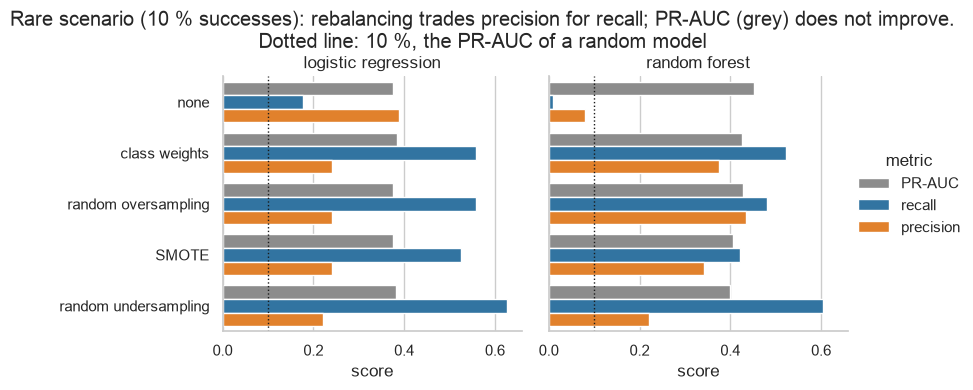

In [4]:
long = rare.reset_index().melt(
    id_vars=["model", "strategy"],
    value_vars=["PR-AUC", "recall", "precision"],
    var_name="metric",
    value_name="score",
)
g = sns.catplot(
    data=long,
    x="score",
    y="strategy",
    hue="metric",
    col="model",
    kind="bar",
    height=3.6,
    aspect=1.2,
    palette=["0.55", "tab:blue", "tab:orange"],
    errorbar=None,
)
g.set_titles("{col_name}")
g.set_axis_labels("score", "")
for ax in g.axes.flat:
    ax.axvline(0.10, color="k", ls=":", lw=1)
g.figure.suptitle(
    "Rare scenario (10 % successes): rebalancing trades precision for recall; PR-AUC (grey) does not improve.\nDotted line: 10 %, the PR-AUC of a random model",
    y=1.08,
)
g.savefig(FIGURES / "03_imbalance_strategies.png", dpi=150, bbox_inches="tight")
plt.show()

**Now the strategies matter, but not in the way people often think.**

* **The untouched random forest finds almost no successes** (recall 0.9 %). With only 1 success in 10 rows, its
  scores rarely reach 0.5, so it almost always says "failure". Its 8 % "precision" is an averaging artefact: in most
  folds it predicted no successes at all, which counts as 0.
* **Every rebalancing strategy raises recall a lot** (to 42–60 % for the forest, 53–63 % for logistic
  regression) **and lowers precision**. Undersampling goes furthest in both directions.
* **PR-AUC, which scores the model across *all* thresholds, does not improve.** For the forest it's slightly *lower*
  after rebalancing (0.45 → 0.40–0.43); for logistic regression it's unchanged (0.38). The models aren't better at
  telling successes from failures; they just say "success" more often.
* **SMOTE was not better than simple oversampling** here.

That suggests rebalancing is mostly a roundabout way of moving the threshold. The next section tests that directly.

## 3 · The threshold is the real lever

> **In plain language.** Every classifier outputs a *score*, and turns it into yes/no by comparing it with a
> threshold (default 0.5). Rebalancing the training data mostly **shifts the scores upwards**, which has the same
> effect as **lowering the threshold**. If that's true, all strategies should sit on (nearly) the same
> precision–recall curve, just at different points.

Below, each strategy's out-of-fold predictions (one rare subset, random forest) are drawn as a full precision–recall
curve, with a dot marking where the default 0.5 threshold puts it.

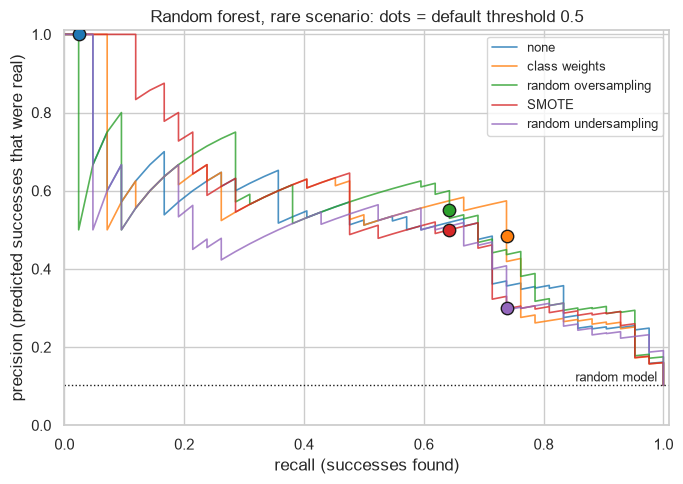

In [5]:
subset = rare_sets[0]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {
    s: cross_val_predict(
        make_pipeline("random forest", s),
        subset[COURSE_FEATURES],
        subset[LABEL],
        groups=subset[GROUP],
        cv=cv,
        method="predict_proba",
    )[:, 1]
    for s in STRATEGIES
}
truth = subset[LABEL].to_numpy()

fig, ax = plt.subplots(figsize=(7, 5))
colors = dict(zip(STRATEGIES, sns.color_palette("tab10", len(STRATEGIES)), strict=True))
for s, score in oof.items():
    prec, rec, _ = precision_recall_curve(truth, score)
    ax.plot(rec, prec, color=colors[s], lw=1.2, alpha=0.8, label=s)
    pred = score >= 0.5
    ax.scatter(
        pred[truth == 1].mean(),
        truth[pred].mean() if pred.any() else np.nan,
        s=80,
        color=colors[s],
        edgecolor="k",
        zorder=3,
    )
ax.axhline(truth.mean(), color="k", ls=":", lw=1)
ax.text(0.99, truth.mean() + 0.01, "random model", ha="right", fontsize=9)
ax.set(
    xlabel="recall (successes found)",
    ylabel="precision (predicted successes that were real)",
    xlim=(0, 1.01),
    ylim=(0, 1.01),
    title="Random forest, rare scenario: dots = default threshold 0.5",
)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "04_threshold_operating_points.png", dpi=150)
plt.show()

Now the direct test: keep the **untouched** model ("none") and only move its threshold until it finds as many
successes as the undersampling model does at 0.5.

In [6]:
def at_threshold(score, t):
    pred = score >= t
    return {
        "threshold": t,
        "recall": pred[truth == 1].mean(),
        "precision": truth[pred].mean(),
        "flagged": int(pred.sum()),
    }


target_recall = at_threshold(oof["random undersampling"], 0.5)["recall"]
thresholds = np.unique(oof["none"])[::-1]
t_match = next(t for t in thresholds if at_threshold(oof["none"], t)["recall"] >= target_recall)
pd.DataFrame(
    {
        "undersampling, threshold 0.5": at_threshold(oof["random undersampling"], 0.5),
        "no rebalancing, threshold 0.5": at_threshold(oof["none"], 0.5),
        "no rebalancing, threshold moved": at_threshold(oof["none"], t_match),
    }
).T.round(3)

,threshold,recall,precision,flagged
"undersampling, threshold 0.5",0.500,0.738,0.301,103.0
"no rebalancing, threshold 0.5",0.500,0.024,1.000,1.0
"no rebalancing, threshold moved",0.171,0.738,0.369,84.0


**Moving the threshold of the untouched model (to 0.17) finds exactly as many successes as undersampling (74 %), with
*higher* precision (37 % vs 30 %) and fewer attempts flagged (84 vs 103).** In the figure, all five curves overlap
broadly. The strategies differ mainly in *where on the curve* the 0.5 threshold lands.

> **In plain language.** Imbalance handling is usually a question of **where to draw the line**, and that line should
> be set by **what each kind of mistake costs**. For MR: a missed success may mean abandoning a solvable structure;
> a false alarm costs computer time. Choose the threshold that gives the recall you need. This keeps all the data
> (undersampling throws data away) and makes the trade-off explicit.
>
> *Caveat:* here the threshold was read off the same cross-validated predictions it is evaluated on, which flatters
> it slightly. In a real project, choose it on validation data and confirm on a test set.

## 4 · Would more data help? Learning curves

> **In plain language.** A **learning curve** trains the model on growing portions of the training data and plots
> the score on the training part and on held-out crystals.
> * If the two curves are **far apart** and the validation curve is **still rising**, more data would help
>   (the model is limited by variance).
> * If both are **low and close together**, more data won't help much; better *features* would (the model is limited
>   by bias).

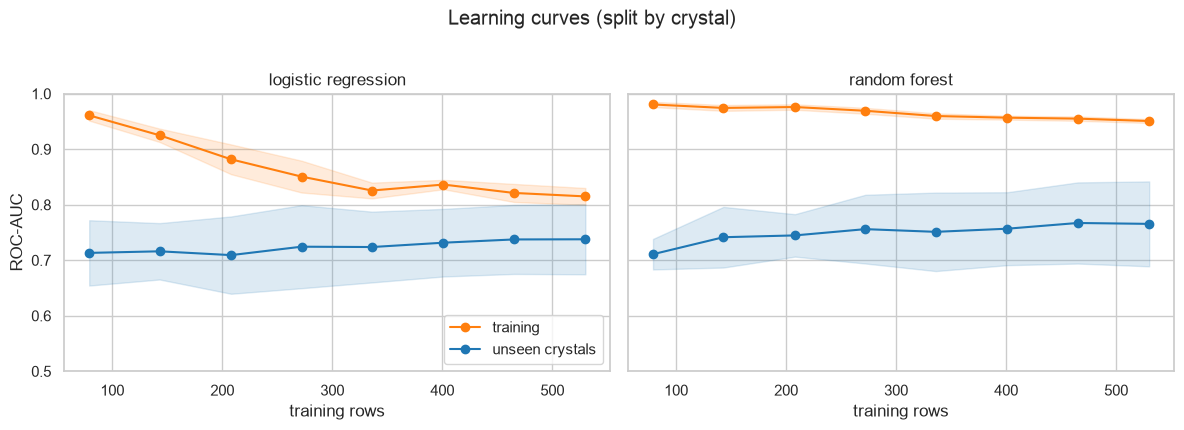

logistic regression: unseen-crystal AUC 0.713 at 79 rows → 0.738 at 530 rows; gap to training at full size 0.077
random forest: unseen-crystal AUC 0.711 at 79 rows → 0.765 at 530 rows; gap to training at full size 0.185


In [7]:
X, y, groups = df[COURSE_FEATURES], df[LABEL], df[GROUP]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
sizes = np.linspace(0.15, 1.0, 8)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
curves = {}
for ax, name in zip(axes, ["logistic regression", "random forest"], strict=True):
    n, train, val = learning_curve(
        make_pipeline(name, "none"),
        X,
        y,
        groups=groups,
        cv=cv,
        train_sizes=sizes,
        scoring="roc_auc",
        n_jobs=4,
    )
    curves[name] = (n, train.mean(1), val.mean(1))
    for scores, label, color in [(train, "training", "tab:orange"), (val, "unseen crystals", "tab:blue")]:
        ax.plot(n, scores.mean(1), marker="o", color=color, label=label)
        ax.fill_between(
            n, scores.mean(1) - scores.std(1), scores.mean(1) + scores.std(1), color=color, alpha=0.15
        )
    ax.set(title=name, xlabel="training rows", ylim=(0.5, 1.0))
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(loc="lower right")
fig.suptitle("Learning curves (split by crystal)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURES / "05_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()
for name, (n, tr, va) in curves.items():
    print(
        f"{name}: unseen-crystal AUC {va[0]:.3f} at {n[0]} rows → {va[-1]:.3f} at {n[-1]} rows; "
        f"gap to training at full size {tr[-1] - va[-1]:.3f}"
    )

* **Logistic regression:** the training score falls and the unseen-crystal score barely rises (0.71 → 0.74 from 79 to
  530 rows). The curves are converging with a gap of only 0.08. **More data of the same kind will help little; the
  model is limited by what the features can express.**
* **Random forest:** the unseen-crystal score is still creeping up (0.71 → 0.77), and the gap to training is large
  (0.19). **More crystals would probably help a little**, but the slope is shallow.
* **For both, the cheapest big improvement is a better feature,** as notebook 01 showed with sequence identity
  (grouped AUC about 0.86–0.88). The learning curves and that experiment point the same way.

## 5 · How complex should the model be? Validation curves, and the split trap again

> **In plain language.** A **validation curve** varies one complexity setting, here the random forest's maximum
> tree depth, and plots training and validation scores. The best setting is where the *validation* score peaks.
> I draw it twice: once with a random split and once split by crystal.

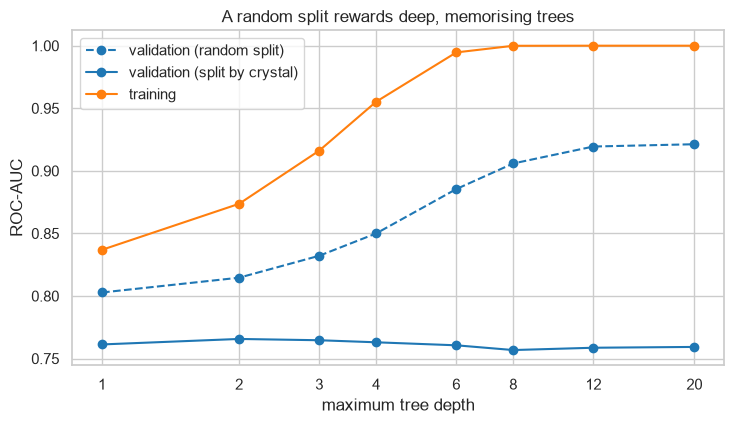

random split: best depth 20 (AUC 0.921); at depth 20: 0.921
split by crystal: best depth 2 (AUC 0.766); at depth 20: 0.759


In [8]:
depths = [1, 2, 3, 4, 6, 8, 12, 20]
forest = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=4)),
    ]
)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
peaks = {}
for split_name, splitter, style in [
    ("random split", StratifiedKFold, "--"),
    ("split by crystal", StratifiedGroupKFold, "-"),
]:
    train, val = validation_curve(
        forest,
        X,
        y,
        groups=groups,
        param_name="model__max_depth",
        param_range=depths,
        cv=splitter(n_splits=5, shuffle=True, random_state=SEED),
        scoring="roc_auc",
    )
    ax.plot(depths, val.mean(1), style, marker="o", color="tab:blue", label=f"validation ({split_name})")
    peaks[split_name] = (depths[int(val.mean(1).argmax())], val.mean(1).max(), val.mean(1)[-1])
ax.plot(depths, train.mean(1), marker="o", color="tab:orange", label="training")
ax.set(
    xscale="log",
    xticks=depths,
    xticklabels=depths,
    xlabel="maximum tree depth",
    ylabel="ROC-AUC",
    title="A random split rewards deep, memorising trees",
)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "06_validation_curve.png", dpi=150)
plt.show()
for split_name, (best_depth, best, deepest) in peaks.items():
    print(f"{split_name}: best depth {best_depth} (AUC {best:.3f}); at depth 20: {deepest:.3f}")

**The two splits give opposite advice.**

* With a **random split**, validation AUC climbs steadily with depth, up to 0.92 at depth 20. The advice would be
  "use deep trees".
* **Split by crystal**, the curve is flat (0.76–0.77) and peaks at **depth 2**. Deep trees add nothing for new
  crystals; their extra "skill" was recognising crystals already seen.

> **In plain language.** A validation curve only tells the truth if its validation data looks like the future. A wrong
> split doesn't just inflate the final number; it also **makes you choose the wrong model**. This is the
> hyperparameter version of section 4 in notebook 01, and it explains why the tutorial's tuned forest is deeper than
> nested grouped CV preferred.

## Conclusions

1. **At the dataset's natural balance (44 %), imbalance handling is unnecessary**: every strategy is within about
   0.01 AUC of doing nothing.
2. **When successes are rare (10 %), the untouched forest finds almost none, and rebalancing raises recall to
   42–63 %**. But PR-AUC doesn't improve: the models don't get better at *ranking*, they just flag more.
3. **Moving the threshold of the plain model matched undersampling's recall (74 %) with higher precision (37 % vs
   30 %).** Set thresholds from the cost of each mistake, on validation data. That is simpler and keeps all the data.
4. **Learning curves:** more data would help the forest slightly and logistic regression hardly at all. **Better
   features** are the better investment.
5. **Validation curves depend on the split:** a random split recommends depth 20 (AUC 0.92); a split by crystal
   recommends depth 2 (0.77). The wrong split picks the wrong model as well as reporting the wrong score.

---
*Data and cleaning as in notebook 01 (`dsls.mr`, tested). Runs in about 3 minutes.*